# Logistic Regression Model:-

> Here is the complete BigQuery ML (BQML) pipeline for training a Logistic Regression classification model on the standard diabetes.csv dataset (Pima Indians Diabetes).

# Key Concepts for Logistic Regression in BQML:-
1. **Model Type**: model_type = 'logistic_reg' is used because the target (Outcome) is binary (0 = No Diabetes, 1 = Diabetes).
2. **Evaluation Metrics**: Instead of R2 and RMSE (which are for continuous numbers), BQML outputs Accuracy, Precision, Recall, F1-Score, Log Loss, and ROC AUC.
3. **Imputation**: In clinical datasets like diabetes.csv, 0 values in columns like Glucose, BloodPressure, BMI, and Insulin are biologically impossible and represent missing data. We replace these 0s with the median.

# Complete BQML Logistic Regression Model Code:-

```sql
-- Create a schema/dataset in the US region
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
OPTIONS(
  location = 'US'
);


-- Cleanse data: Replace impossible 0s with median values
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_diabetes` AS
WITH medians AS (
  SELECT
    APPROX_QUANTILES(IF(Glucose > 0, Glucose, NULL), 2)[OFFSET(1)] AS med_glucose,
    APPROX_QUANTILES(IF(BloodPressure > 0, BloodPressure, NULL), 2)[OFFSET(1)] AS med_bp,
    APPROX_QUANTILES(IF(SkinThickness > 0, SkinThickness, NULL), 2)[OFFSET(1)] AS med_skin,
    APPROX_QUANTILES(IF(Insulin > 0, Insulin, NULL), 2)[OFFSET(1)] AS med_insulin,
    APPROX_QUANTILES(IF(BMI > 0, BMI, NULL), 2)[OFFSET(1)] AS med_bmi
  FROM `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_diabetes`
)
SELECT
  Pregnancies,
  IF(Glucose = 0, (SELECT med_glucose FROM medians), Glucose) AS Glucose,
  IF(BloodPressure = 0, (SELECT med_bp FROM medians), BloodPressure) AS BloodPressure,
  IF(SkinThickness = 0, (SELECT med_skin FROM medians), SkinThickness) AS SkinThickness,
  IF(Insulin = 0, (SELECT med_insulin FROM medians), Insulin) AS Insulin,
  IF(BMI = 0, (SELECT med_bmi FROM medians), BMI) AS BMI,
  DiabetesPedigreeFunction,
  Age,
  -- Cast Outcome to INT64 or STRING so BigQuery treats it as a classification label
  CAST(Outcome AS INT64) AS Outcome 
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_diabetes`;



-- Train the BQML Logistic Regression model
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`
OPTIONS (
  model_type = 'logistic_reg',
  input_label_cols = ['Outcome'],
  
  -- Split 80% for training and 20% for testing
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  
  -- Automatically handle class balance (more non-diabetic than diabetic patients)
  auto_class_weights = TRUE,
  
  -- Optional L2 Regularization (similar to Ridge)
  l2_reg = 0.1
) AS
SELECT
  Pregnancies,
  Glucose,
  BloodPressure,
  SkinThickness,
  Insulin,
  BMI,
  DiabetesPedigreeFunction,
  Age,
  Outcome
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_diabetes`;



-- Evaluate classification metrics
SELECT
  *
FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`);



-- Evaluate confusion matrix on the test split
SELECT
  *
FROM
  ML.CONFUSION_MATRIX(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`);



-- Check model weights/coefficients
SELECT
  processed_input,
  weight
FROM
  ML.WEIGHTS(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`)
ORDER BY 
  ABS(weight) DESC;



-- Make predictions on two new hypothetical patients (with exact data types)
SELECT
  predicted_Outcome,
  predicted_Outcome_probs,
  Glucose,
  BMI,
  Age
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`,
    (
      -- Patient 1: Low risk profile
      SELECT 
        CAST(1 AS INT64) AS Pregnancies,
        CAST(85 AS INT64) AS Glucose,
        CAST(66 AS INT64) AS BloodPressure,
        CAST(29 AS INT64) AS SkinThickness,
        CAST(0 AS INT64) AS Insulin,
        CAST(26.6 AS FLOAT64) AS BMI,
        CAST(0.351 AS FLOAT64) AS DiabetesPedigreeFunction,
        CAST(31 AS INT64) AS Age
      UNION ALL
      -- Patient 2: High risk profile
      SELECT 
        CAST(8 AS INT64) AS Pregnancies,
        CAST(180 AS INT64) AS Glucose,
        CAST(90 AS INT64) AS BloodPressure,
        CAST(40 AS INT64) AS SkinThickness,
        CAST(150 AS INT64) AS Insulin,
        CAST(42.1 AS FLOAT64) AS BMI,
        CAST(0.950 AS FLOAT64) AS DiabetesPedigreeFunction,
        CAST(55 AS INT64) AS Age
    )
  );



-- Cleanup resources
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_diabetes`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_diabetes`;
DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox` CASCADE;
```

# Complete step by step guide for Logistic Regression Model:-
- **Step 1**: Create the Schema (Dataset)
```sql
-- Create a schema/dataset in the US region
CREATE SCHEMA IF NOT EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox`
OPTIONS(
  location = 'US'
);
```

---

- **Step 2**: Cleanse and Impute Missing Values (Zeros) -> In the diabetes dataset, zero values in biological measurements are missing values. We replace them with the median of the non-zero values.
```sql
-- Cleanse data: Replace impossible 0s with median values
CREATE OR REPLACE TABLE `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_diabetes` AS
WITH medians AS (
  SELECT
    APPROX_QUANTILES(IF(Glucose > 0, Glucose, NULL), 2)[OFFSET(1)] AS med_glucose,
    APPROX_QUANTILES(IF(BloodPressure > 0, BloodPressure, NULL), 2)[OFFSET(1)] AS med_bp,
    APPROX_QUANTILES(IF(SkinThickness > 0, SkinThickness, NULL), 2)[OFFSET(1)] AS med_skin,
    APPROX_QUANTILES(IF(Insulin > 0, Insulin, NULL), 2)[OFFSET(1)] AS med_insulin,
    APPROX_QUANTILES(IF(BMI > 0, BMI, NULL), 2)[OFFSET(1)] AS med_bmi
  FROM `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_diabetes`
)
SELECT
  Pregnancies,
  IF(Glucose = 0, (SELECT med_glucose FROM medians), Glucose) AS Glucose,
  IF(BloodPressure = 0, (SELECT med_bp FROM medians), BloodPressure) AS BloodPressure,
  IF(SkinThickness = 0, (SELECT med_skin FROM medians), SkinThickness) AS SkinThickness,
  IF(Insulin = 0, (SELECT med_insulin FROM medians), Insulin) AS Insulin,
  IF(BMI = 0, (SELECT med_bmi FROM medians), BMI) AS BMI,
  DiabetesPedigreeFunction,
  Age,
  -- Cast Outcome to INT64 or STRING so BigQuery treats it as a classification label
  CAST(Outcome AS INT64) AS Outcome 
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_diabetes`;
```
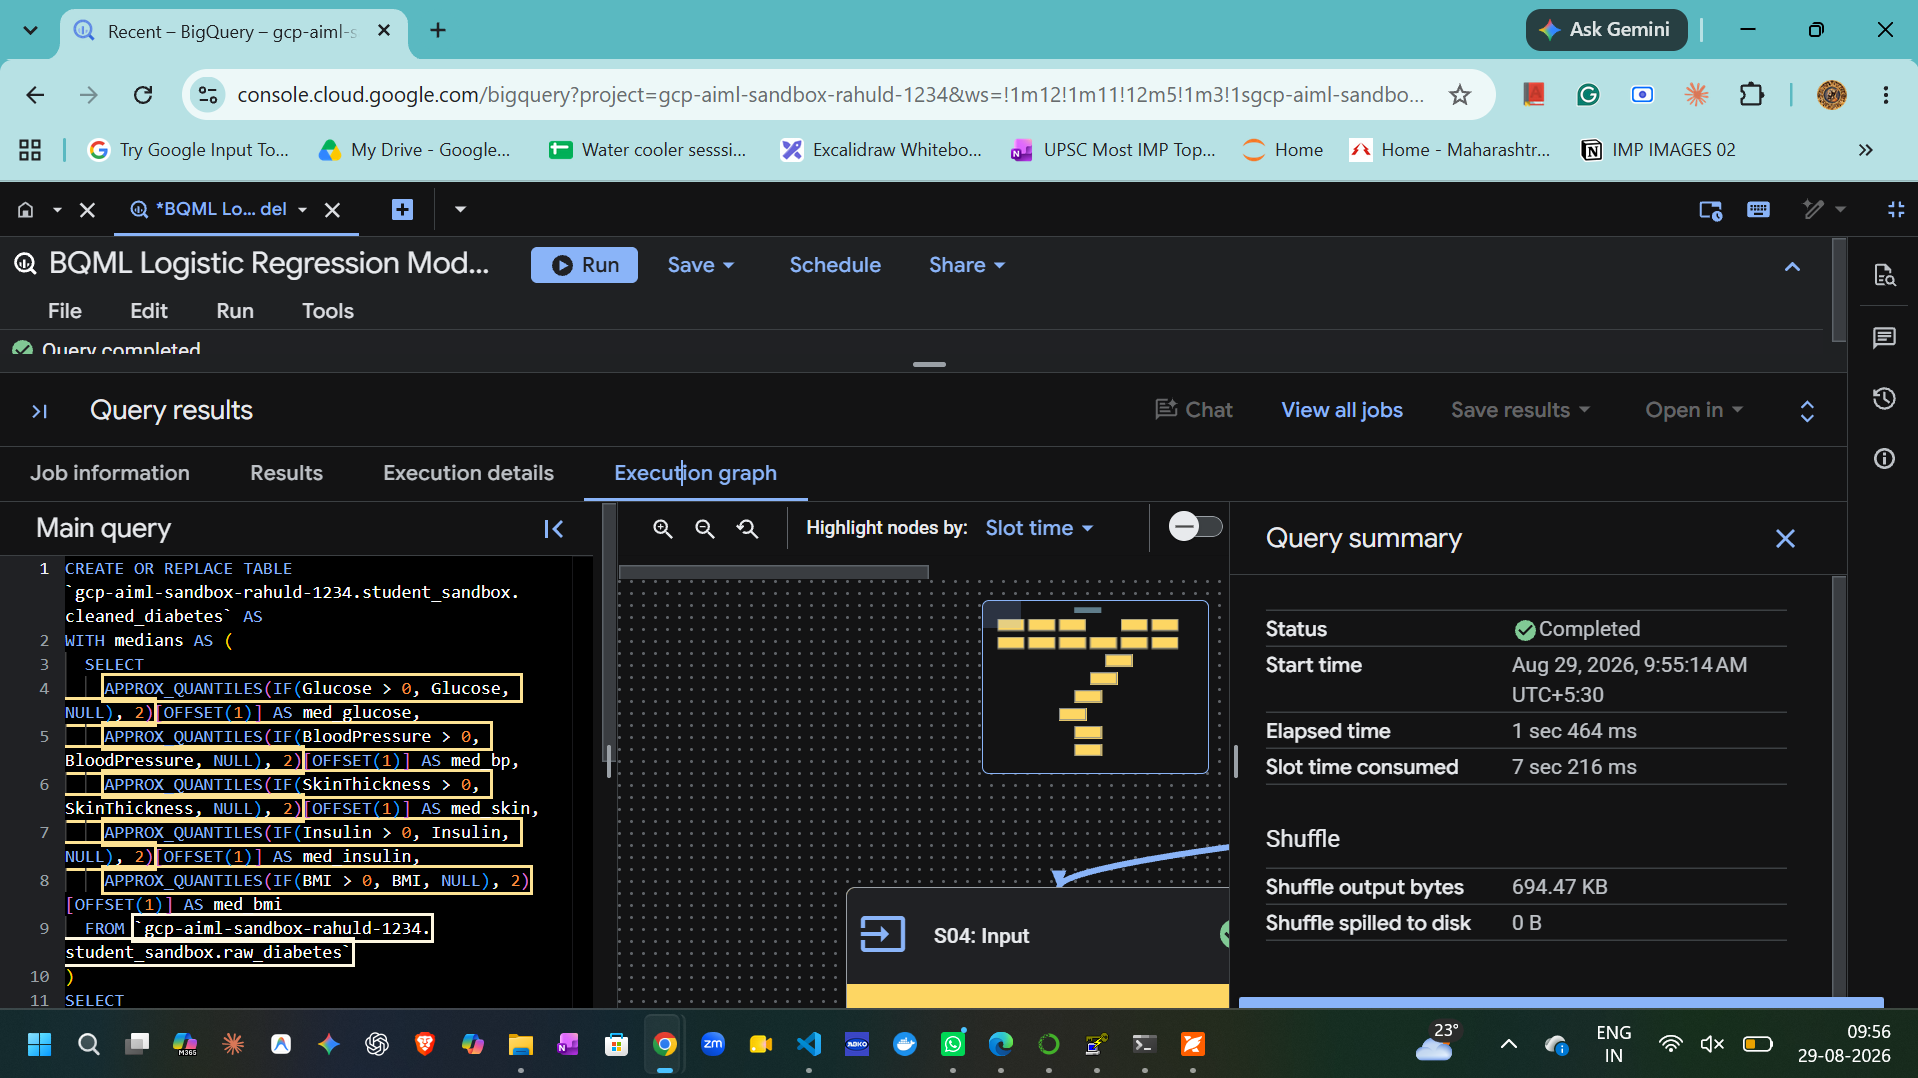

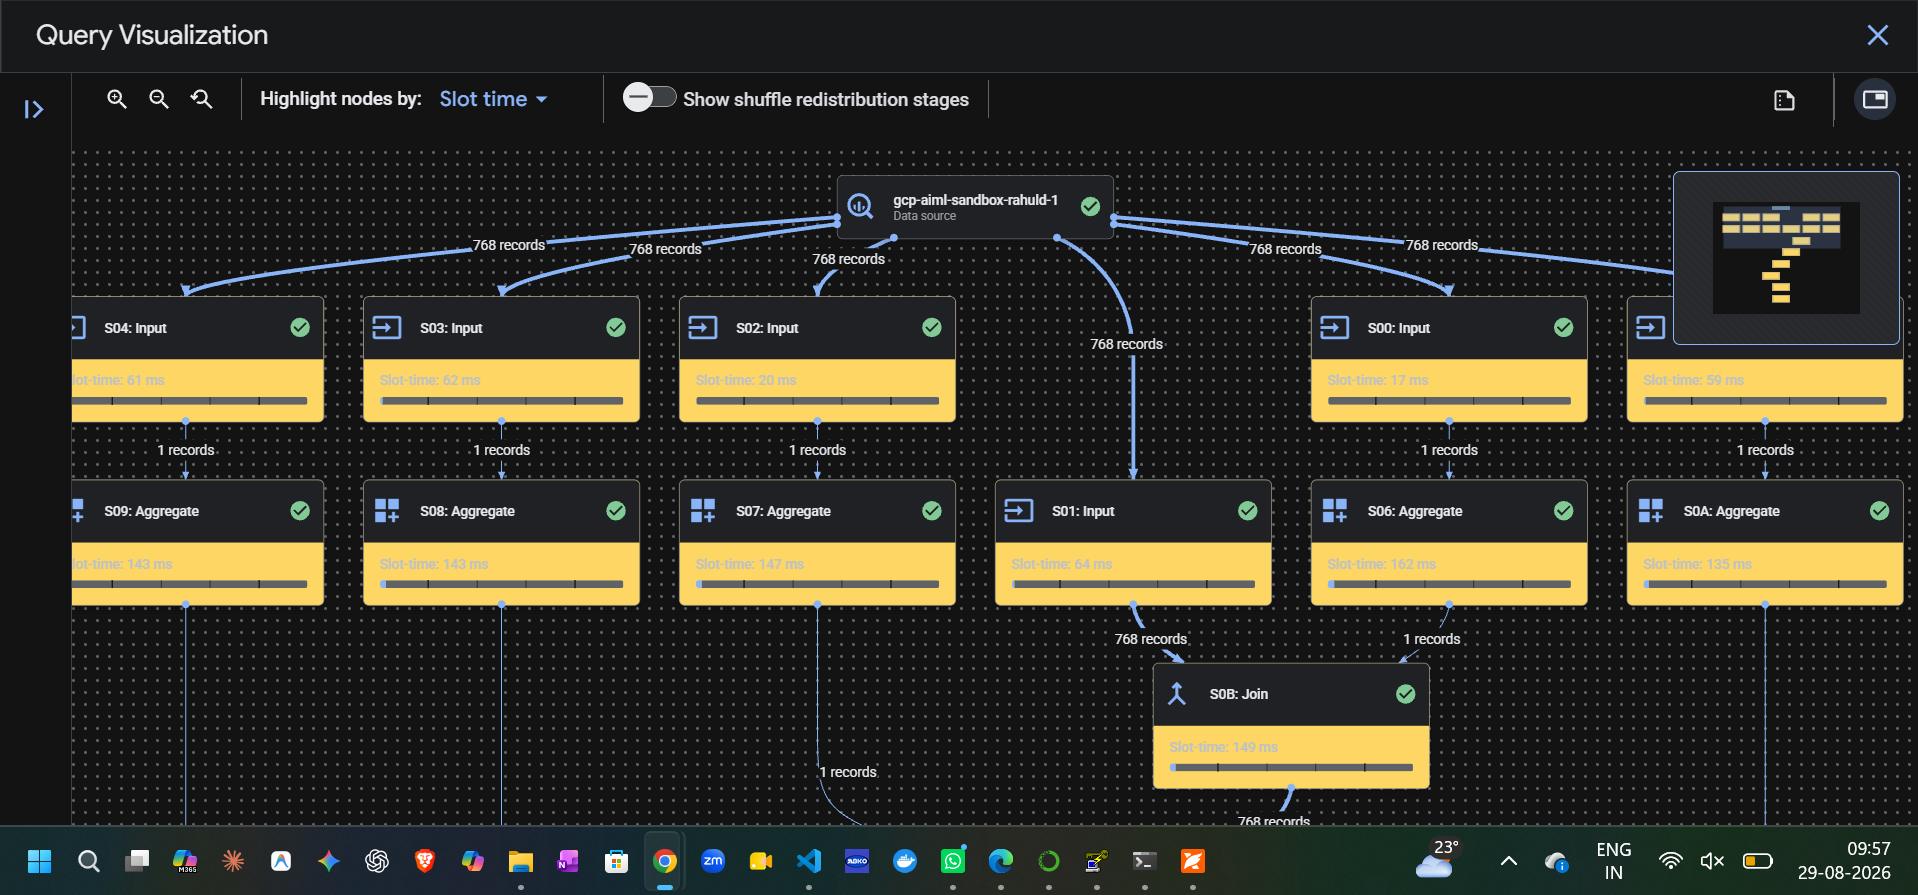

---

- **Step 3**: Train the Logistic Regression Model
```sql
-- Train the BQML Logistic Regression model
CREATE OR REPLACE MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`
OPTIONS (
  model_type = 'logistic_reg',
  input_label_cols = ['Outcome'],
  
  -- Split 80% for training and 20% for testing
  data_split_method = 'RANDOM',
  data_split_eval_fraction = 0.2,
  
  -- Automatically handle class balance (more non-diabetic than diabetic patients)
  auto_class_weights = TRUE,
  
  -- Optional L2 Regularization (similar to Ridge)
  l2_reg = 0.1
) AS
SELECT
  Pregnancies,
  Glucose,
  BloodPressure,
  SkinThickness,
  Insulin,
  BMI,
  DiabetesPedigreeFunction,
  Age,
  Outcome
FROM
  `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_diabetes`;
```
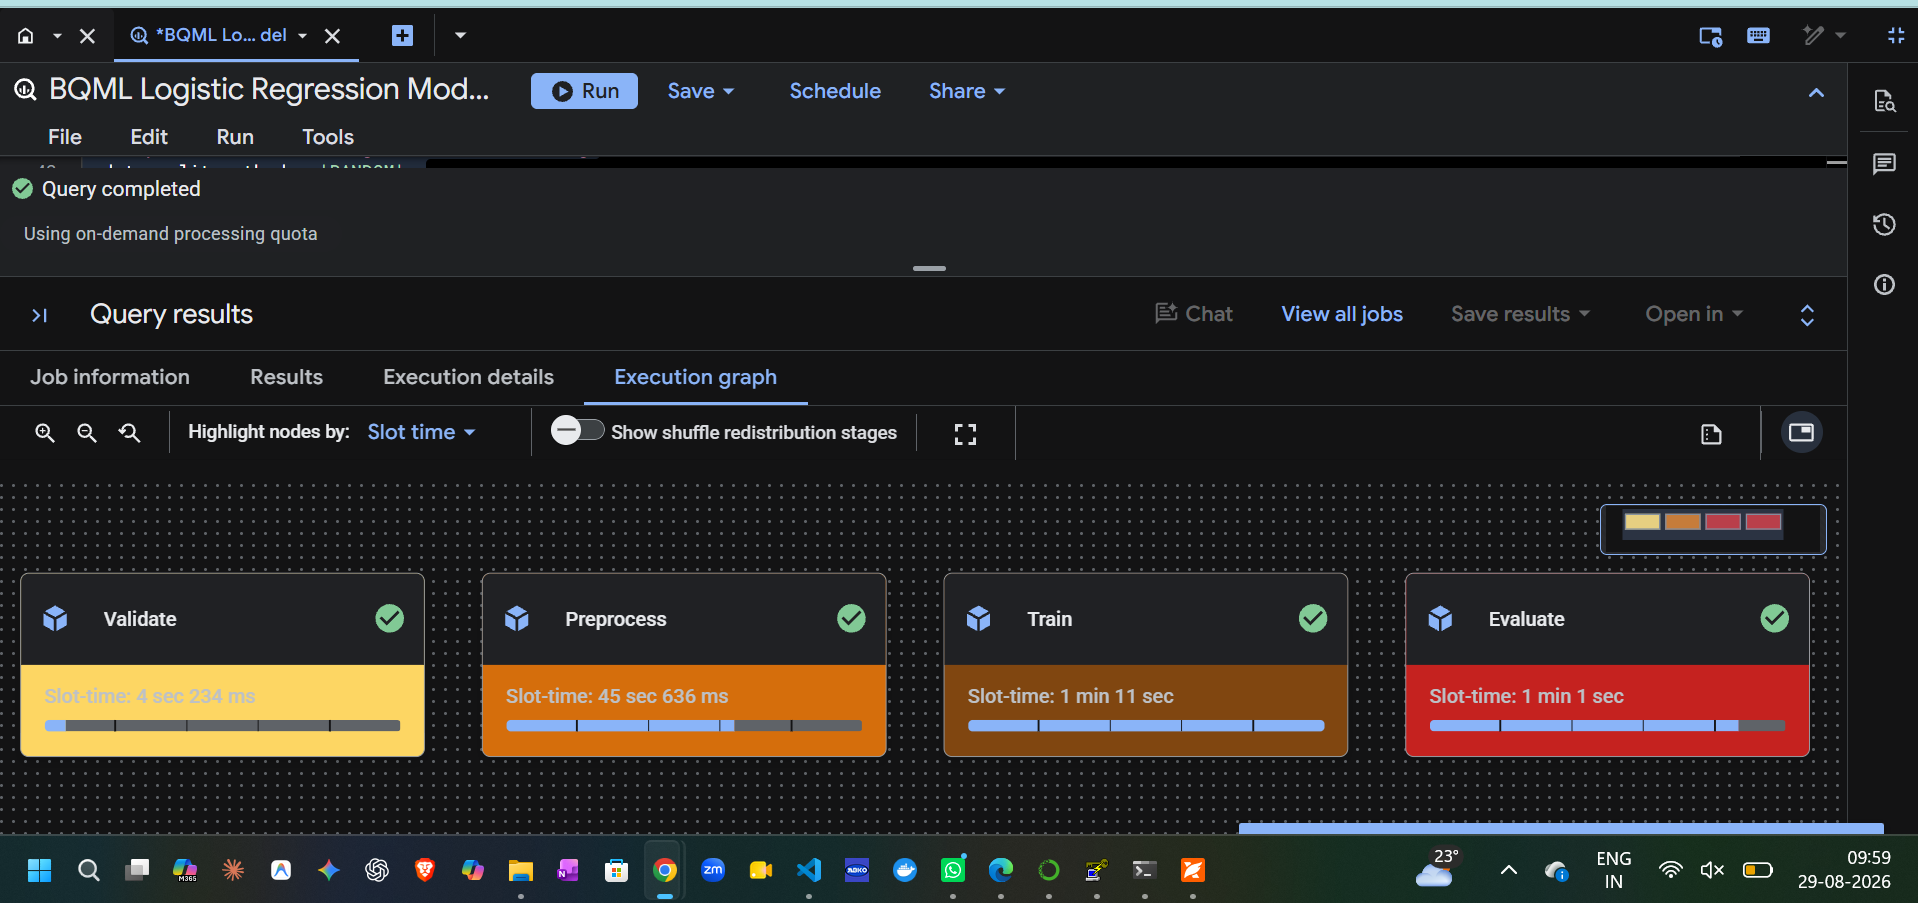

---

- **Step 4**: Evaluate the Classification Performance -> This returns metrics like Accuracy, Precision, Recall, F1-score, and ROC-AUC (values closer to 1.0 are better).
```sql
-- Evaluate classification metrics
SELECT
  *
FROM
  ML.EVALUATE(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`);
```
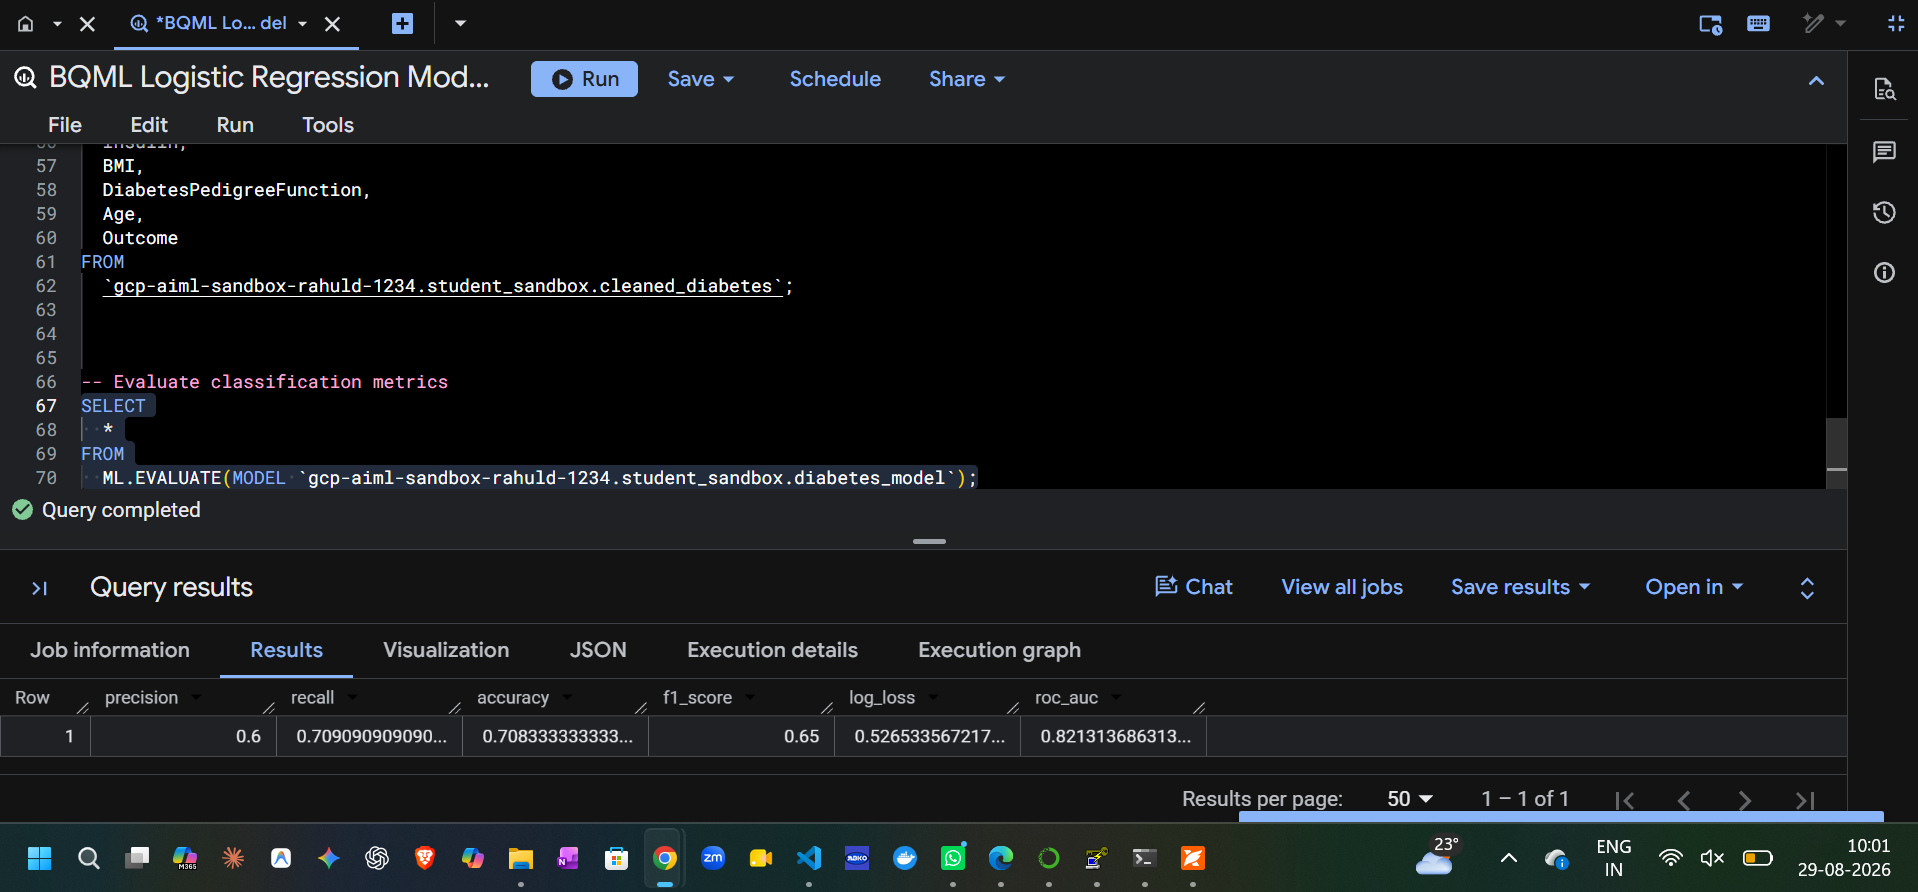

---

- **Step 5**: Generate Confusion Matrix -> Check where the model is making False Positive vs False Negative mistakes:
```sql
-- Evaluate confusion matrix on the test split
SELECT
  *
FROM
  ML.CONFUSION_MATRIX(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`);
```
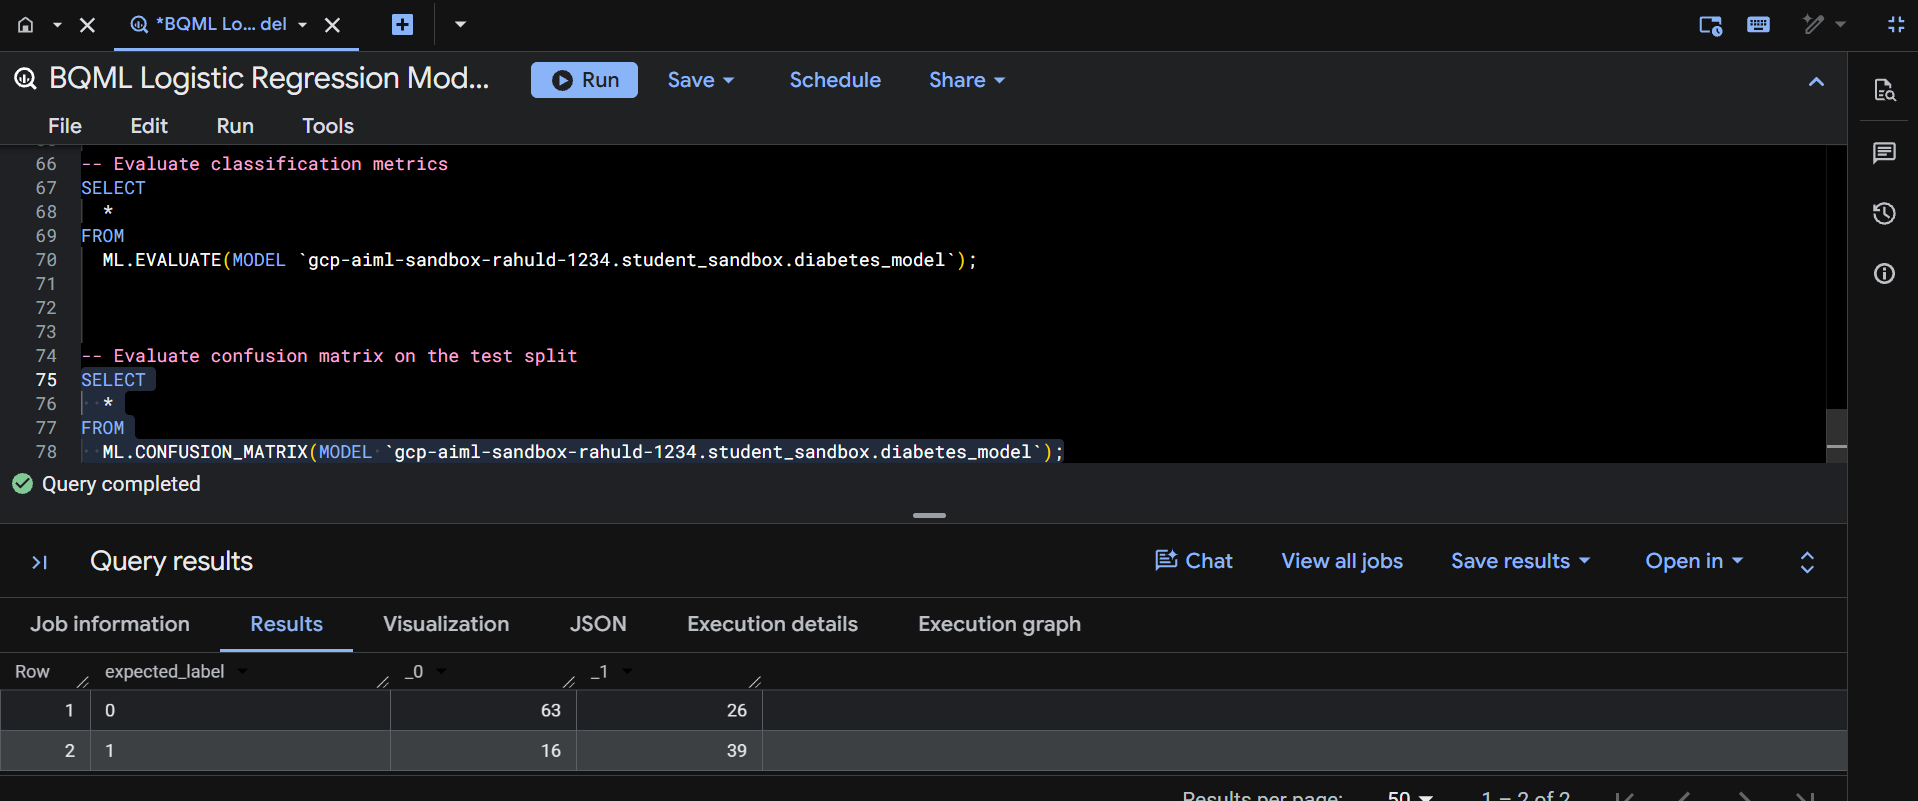

---

- **Step 6**: View Feature Importance & Weights (Coefficients) -> See which health metrics are the strongest risk indicators for diabetes (e.g., Glucose, BMI, Age).
```sql
-- Check model weights/coefficients
SELECT
  processed_input,
  weight
FROM
  ML.WEIGHTS(MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`)
ORDER BY 
  ABS(weight) DESC;
```
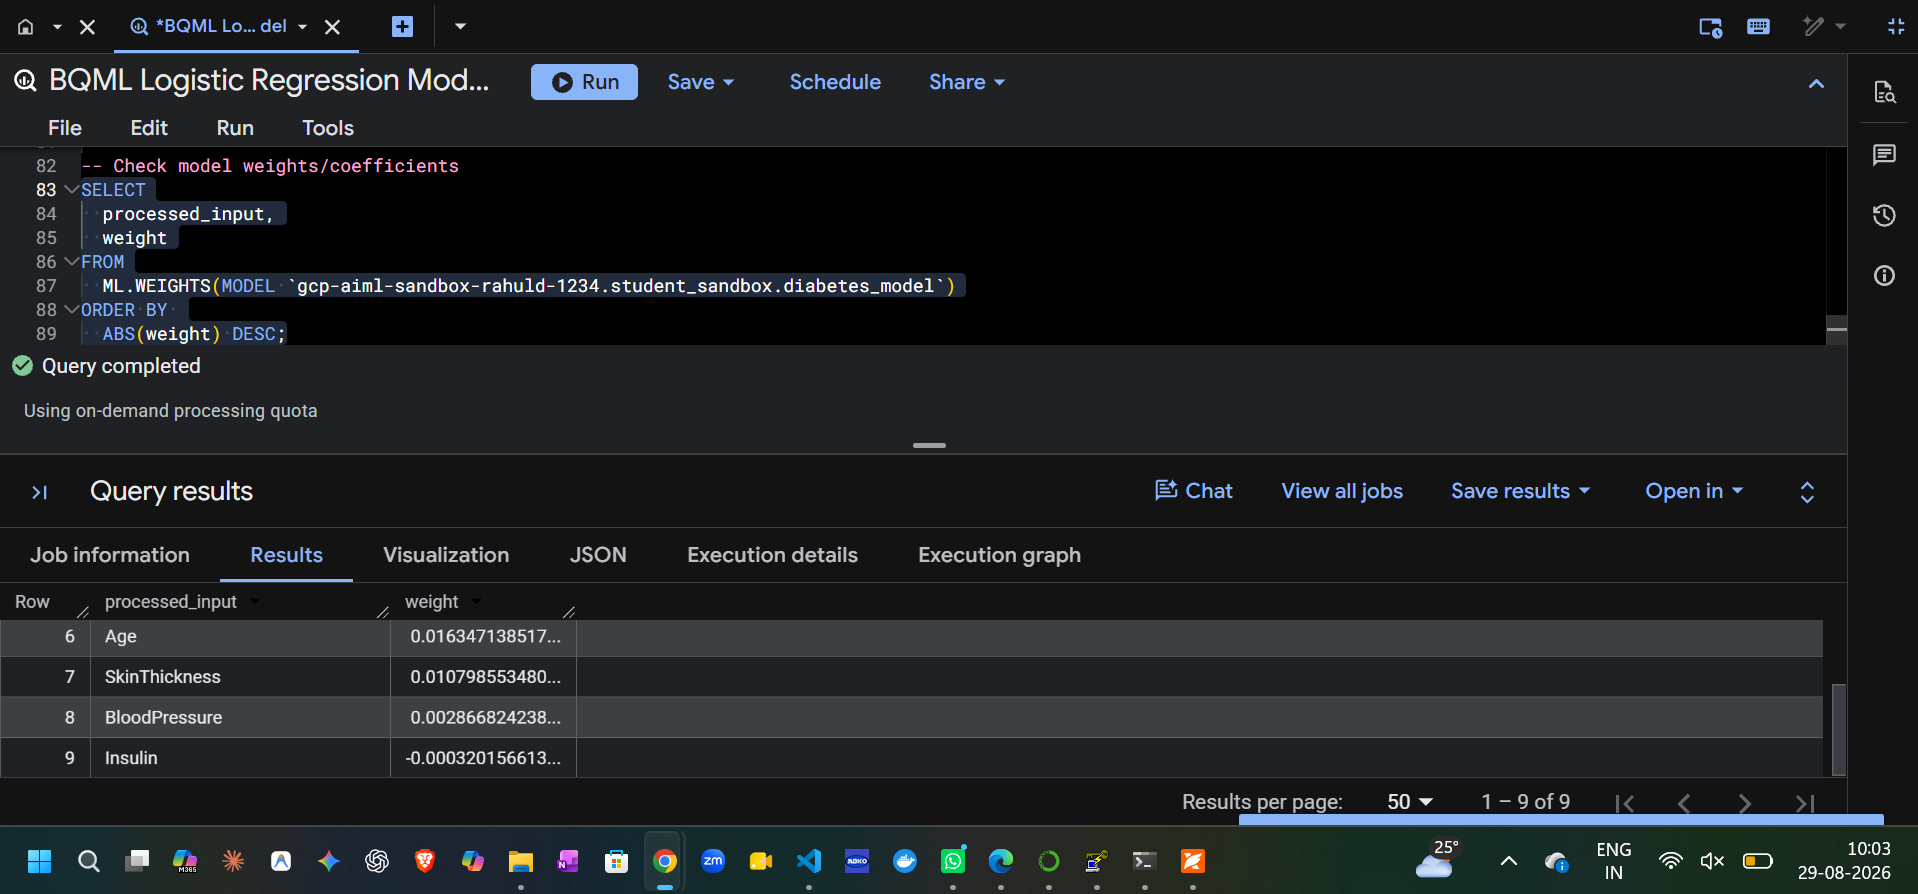

---

- **Step 7**: Predict on Unseen Patients -> The query returns predicted_Outcome (0 or 1) and an array predicted_Outcome_probs showing the confidence percentage for both classes.
```sql
-- Make predictions on two new hypothetical patients (with exact data types)
SELECT
  predicted_Outcome,
  predicted_Outcome_probs,
  Glucose,
  BMI,
  Age
FROM
  ML.PREDICT(
    MODEL `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`,
    (
      -- Patient 1: Low risk profile
      SELECT 
        CAST(1 AS INT64) AS Pregnancies,
        CAST(85 AS INT64) AS Glucose,
        CAST(66 AS INT64) AS BloodPressure,
        CAST(29 AS INT64) AS SkinThickness,
        CAST(0 AS INT64) AS Insulin,
        CAST(26.6 AS FLOAT64) AS BMI,
        CAST(0.351 AS FLOAT64) AS DiabetesPedigreeFunction,
        CAST(31 AS INT64) AS Age
      UNION ALL
      -- Patient 2: High risk profile
      SELECT 
        CAST(8 AS INT64) AS Pregnancies,
        CAST(180 AS INT64) AS Glucose,
        CAST(90 AS INT64) AS BloodPressure,
        CAST(40 AS INT64) AS SkinThickness,
        CAST(150 AS INT64) AS Insulin,
        CAST(42.1 AS FLOAT64) AS BMI,
        CAST(0.950 AS FLOAT64) AS DiabetesPedigreeFunction,
        CAST(55 AS INT64) AS Age
    )
  );
```
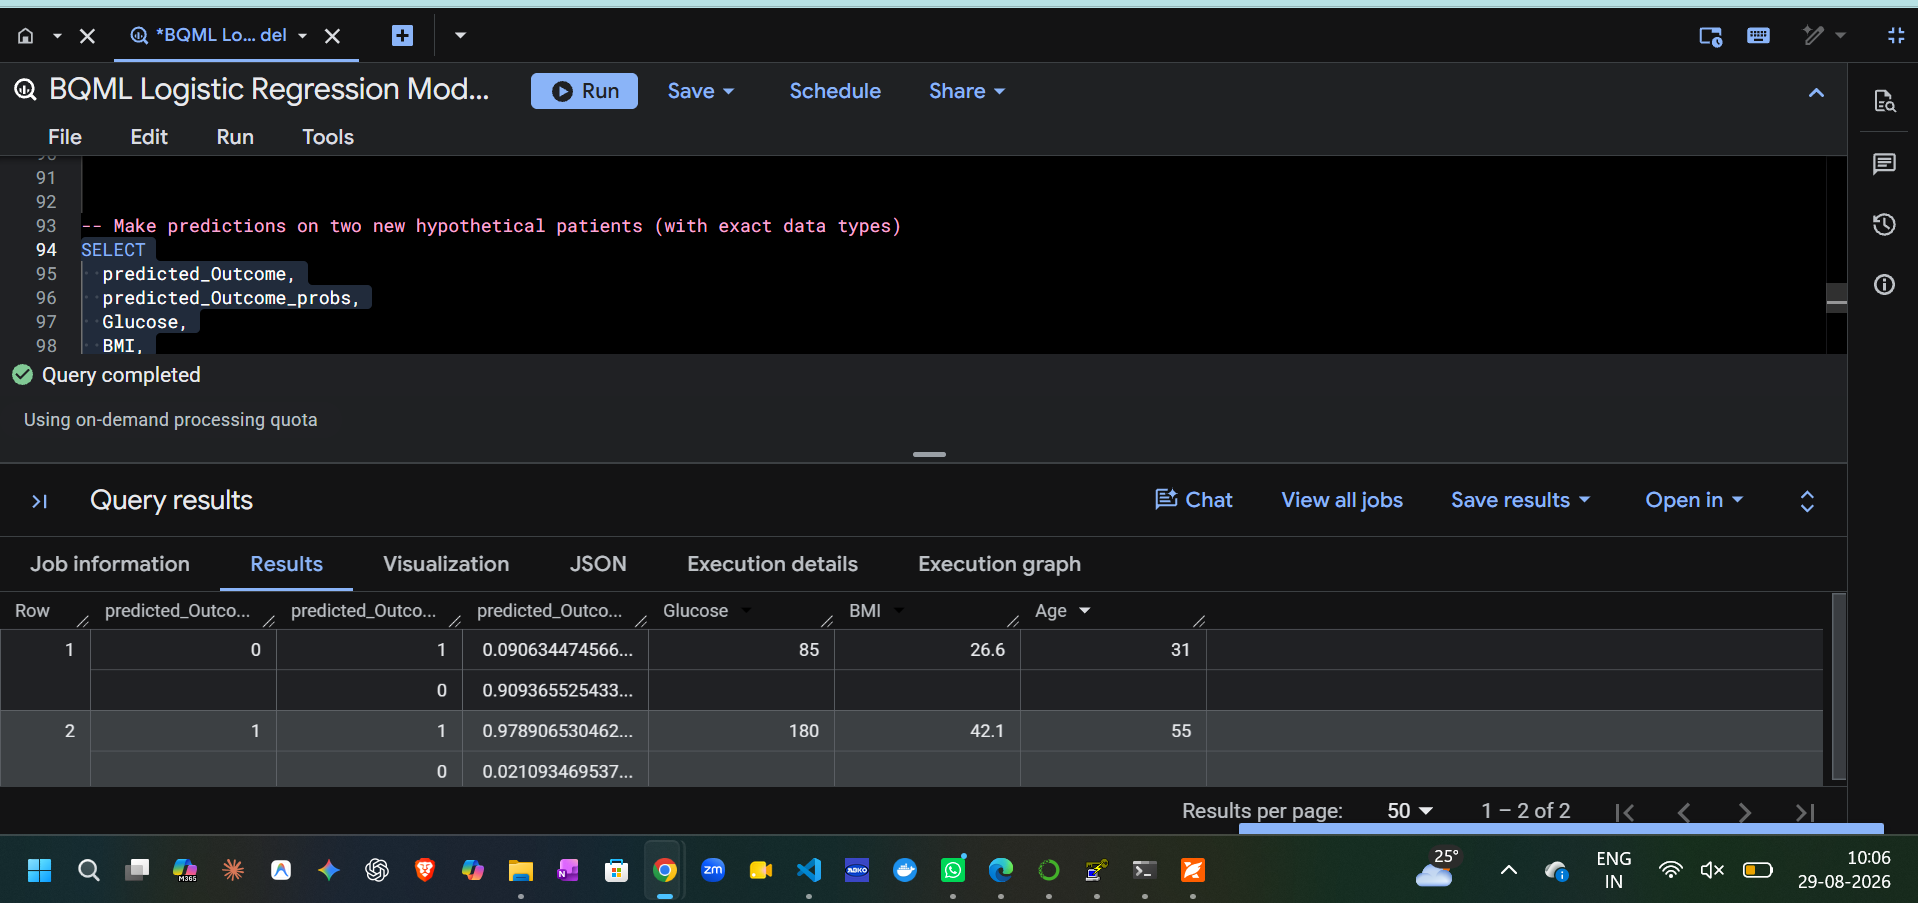

---

- **Step 8**: Clean Up All Resources (Optional) -> Run this when you are done to remove models and tables:
```sql
-- Cleanup resources
DROP MODEL IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.diabetes_model`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.cleaned_diabetes`;
DROP TABLE IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox.raw_diabetes`;
DROP SCHEMA IF EXISTS `gcp-aiml-sandbox-rahuld-1234.student_sandbox` CASCADE;
```

---